In [1]:
import pandas as pd
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = [
    file for file in os.listdir(DATASET_PATH)
    if file.endswith(".csv")
]

print("Number of CSV files:", len(files))

for file in sorted(files):
    path = os.path.join(DATASET_PATH, file)
    print(f"{file}: {os.path.getsize(path) / (1024**2):.2f} MB")
    

Number of CSV files: 8
Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: 73.55 MB
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: 73.34 MB
Friday-WorkingHours-Morning.pcap_ISCX.csv: 55.62 MB
Monday-WorkingHours.pcap_ISCX.csv: 168.73 MB
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: 79.25 MB
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: 49.61 MB
Tuesday-WorkingHours.pcap_ISCX.csv: 128.82 MB
Wednesday-workingHours.pcap_ISCX.csv: 214.74 MB


In [2]:
import pandas as pd
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

schemas = {}

for file in files:
    path = os.path.join(DATASET_PATH, file)

    # Read only the column headers, not the entire dataset
    df_header = pd.read_csv(path, nrows=0, encoding="utf-8-sig")

    columns = [col.strip() for col in df_header.columns]
    schemas[file] = columns

    print(f"\nFile: {file}")
    print("Number of columns:", len(columns))

# Check whether all files share the same schema
reference_columns = list(schemas.values())[0]

print("\nAll files have identical columns:",
      all(cols == reference_columns for cols in schemas.values()))

print("\nDataset columns:")
for i, column in enumerate(reference_columns, 1):
    print(f"{i}. {column}")


File: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Number of columns: 79

File: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Number of columns: 79

File: Friday-WorkingHours-Morning.pcap_ISCX.csv
Number of columns: 79

File: Monday-WorkingHours.pcap_ISCX.csv
Number of columns: 79

File: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Number of columns: 79

File: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Number of columns: 79

File: Tuesday-WorkingHours.pcap_ISCX.csv
Number of columns: 79

File: Wednesday-workingHours.pcap_ISCX.csv
Number of columns: 79

All files have identical columns: True

Dataset columns:
1. Destination Port
2. Flow Duration
3. Total Fwd Packets
4. Total Backward Packets
5. Total Length of Fwd Packets
6. Total Length of Bwd Packets
7. Fwd Packet Length Max
8. Fwd Packet Length Min
9. Fwd Packet Length Mean
10. Fwd Packet Length Std
11. Bwd Packet Length Max
12. Bwd Packet Length Min
13. Bwd Packet Length Mean
14. Bwd Packet Len

In [3]:
reference_columns = list(schemas.values())[0]

print("All files have identical columns:",
      all(cols == reference_columns for cols in schemas.values()))

print("\nTarget column exists:", "Label" in reference_columns)

print("Total input features:",
      len(reference_columns) - 1)

print("\nFirst 10 columns:")
print(reference_columns[:10])

print("\nLast 10 columns:")
print(reference_columns[-10:])

All files have identical columns: True

Target column exists: True
Total input features: 78

First 10 columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

Last 10 columns:
['min_seg_size_forward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min', 'Label']


In [4]:

from collections import Counter
import pandas as pd
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

label_counts = Counter()

for file in files:
    path = os.path.join(DATASET_PATH, file)

    print("Processing:", file)

    for chunk in pd.read_csv(
        path,
        usecols=lambda col: col.strip() == "Label",
        chunksize=200_000,
        encoding="utf-8-sig"
    ):
        labels = chunk.iloc[:, 0].astype(str).str.strip()
        label_counts.update(labels.value_counts().to_dict())

# Convert results into a DataFrame
distribution = pd.DataFrame(
    label_counts.items(),
    columns=["Traffic Class", "Number of Records"]
)

distribution = distribution.sort_values(
    by="Number of Records",
    ascending=False
).reset_index(drop=True)

distribution["Percentage"] = (
    distribution["Number of Records"] /
    distribution["Number of Records"].sum() * 100
).round(2)

print("\nCLASS DISTRIBUTION")
print(distribution.to_string(index=False))

print("\nTotal records:", distribution["Number of Records"].sum())



Processing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Processing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Processing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Processing: Monday-WorkingHours.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Processing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Processing: Tuesday-WorkingHours.pcap_ISCX.csv
Processing: Wednesday-workingHours.pcap_ISCX.csv

CLASS DISTRIBUTION
             Traffic Class  Number of Records  Percentage
                    BENIGN            2273097       80.30
                  DoS Hulk             231073        8.16
                  PortScan             158930        5.61
                      DDoS             128027        4.52
             DoS GoldenEye              10293        0.36
               FTP-Patator               7938        0.28
               SSH-Patator               5897        0.21
             DoS slowloris               5796        0.

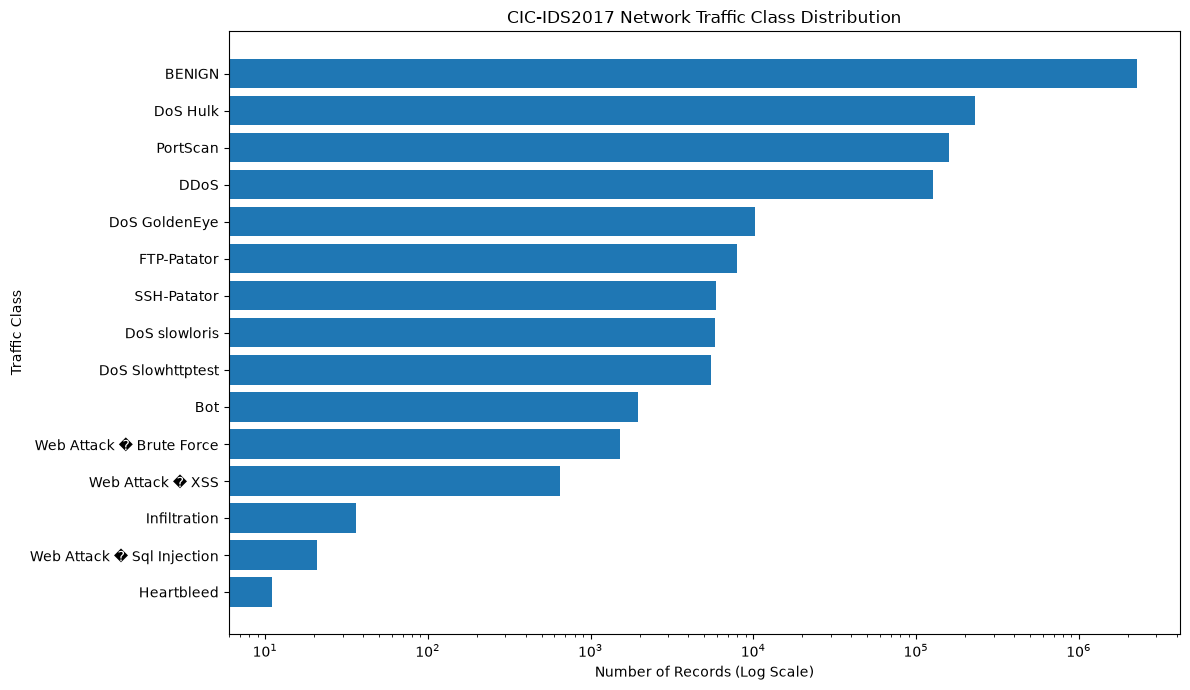

In [5]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

plt.barh(
    distribution["Traffic Class"],
    distribution["Number of Records"]
)

plt.xscale("log")
plt.xlabel("Number of Records (Log Scale)")
plt.ylabel("Traffic Class")
plt.title("CIC-IDS2017 Network Traffic Class Distribution")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "../results/figures/class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:
reference_columns = list(schemas.values())[0]

print("All files have identical columns:",
      all(cols == reference_columns for cols in schemas.values()))

print("\nTarget column exists:", "Label" in reference_columns)

print("Total input features:",
      len(reference_columns) - 1)

print("\nFirst 10 columns:")
print(reference_columns[:10])

print("\nLast 10 columns:")
print(reference_columns[-10:])

All files have identical columns: True

Target column exists: True
Total input features: 78

First 10 columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']

Last 10 columns:
['min_seg_size_forward', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min', 'Label']


In [7]:

import pandas as pd
import numpy as np
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

total_missing = 0
total_infinite = 0

for file in files:
    print("\nChecking:", file)

    path = os.path.join(DATASET_PATH, file)

    missing = 0
    infinite = 0

    for chunk in pd.read_csv(path, chunksize=200_000,
                             encoding="utf-8-sig"):
        chunk.columns = chunk.columns.str.strip()

        missing += chunk.isna().sum().sum()

        numeric = chunk.drop(columns=["Label"])
        numeric = numeric.apply(pd.to_numeric, errors="coerce")

        infinite += np.isinf(numeric.to_numpy()).sum()

    total_missing += missing
    total_infinite += infinite

    print("Missing values:", missing)
    print("Infinite values:", infinite)

print("\n========== FINAL RESULTS ==========")
print("Total missing values:", total_missing)
print("Total infinite values:", total_infinite)



Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Missing values: 4
Infinite values: 64

Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Missing values: 15
Infinite values: 727

Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv
Missing values: 28
Infinite values: 216

Checking: Monday-WorkingHours.pcap_ISCX.csv
Missing values: 64
Infinite values: 810

Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Missing values: 18
Infinite values: 396

Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Missing values: 20
Infinite values: 250

Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Missing values: 201
Infinite values: 327

Checking: Wednesday-workingHours.pcap_ISCX.csv
Missing values: 1008
Infinite values: 1586

========== FINAL RESULTS ==========
Total missing values: 1358
Total infinite values: 4376


In [8]:

import pandas as pd
import numpy as np
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

missing_counts = {}
infinite_counts = {}

for file in files:
    print("Analysing:", file)

    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=200_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        # Count missing values by feature
        for col, count in chunk.isna().sum().items():
            missing_counts[col] = (
                missing_counts.get(col, 0) + count
            )

        # Count infinite values by numeric feature
        numeric = chunk.drop(columns=["Label"])

        numeric = numeric.apply(
            pd.to_numeric, errors="coerce"
        )

        for col in numeric.columns:
            count = np.isinf(numeric[col]).sum()

            infinite_counts[col] = (
                infinite_counts.get(col, 0) + count
            )

missing_df = pd.Series(
    missing_counts, name="Missing"
)

infinite_df = pd.Series(
    infinite_counts, name="Infinite"
)

quality_report = pd.concat(
    [missing_df, infinite_df], axis=1
).fillna(0).astype(int)

quality_report = quality_report[
    (quality_report["Missing"] > 0) |
    (quality_report["Infinite"] > 0)
]

print("\nFEATURES WITH DATA QUALITY ISSUES:")
print(quality_report.sort_values(
    by=["Infinite", "Missing"],
    ascending=False
).to_string())

print("\nAffected feature count:", len(quality_report))


Analysing: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Analysing: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Analysing: Friday-WorkingHours-Morning.pcap_ISCX.csv
Analysing: Monday-WorkingHours.pcap_ISCX.csv
Analysing: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Analysing: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Analysing: Tuesday-WorkingHours.pcap_ISCX.csv
Analysing: Wednesday-workingHours.pcap_ISCX.csv

FEATURES WITH DATA QUALITY ISSUES:
                Missing  Infinite
Flow Packets/s        0      2867
Flow Bytes/s       1358      1509

Affected feature count: 2


In [9]:

import pandas as pd
import numpy as np
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

affected_counts = {}

for file in files:
    print("Checking:", file)

    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=200_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        for feature in ["Flow Packets/s", "Flow Bytes/s"]:

            values = pd.to_numeric(
                chunk[feature], errors="coerce"
            )

            invalid = values.isna() | np.isinf(values)

            counts = (
                chunk.loc[invalid, "Label"]
                .astype(str)
                .value_counts()
            )

            for label, count in counts.items():
                key = (feature, label)

                affected_counts[key] = (
                    affected_counts.get(key, 0) + count
                )

report = pd.DataFrame([
    {
        "Feature": feature,
        "Traffic Class": label,
        "Affected Records": count
    }
    for (feature, label), count in affected_counts.items()
])

print("\nINVALID VALUES BY TRAFFIC CLASS")
print(
    report.sort_values(
        ["Feature", "Affected Records"],
        ascending=[True, False]
    ).to_string(index=False)
)


Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv
Checking: Monday-WorkingHours.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Checking: Wednesday-workingHours.pcap_ISCX.csv

INVALID VALUES BY TRAFFIC CLASS
       Feature Traffic Class  Affected Records
  Flow Bytes/s        BENIGN              1777
  Flow Bytes/s      DoS Hulk               949
  Flow Bytes/s      PortScan               126
  Flow Bytes/s           Bot                10
  Flow Bytes/s   FTP-Patator                 3
  Flow Bytes/s          DDoS                 2
Flow Packets/s        BENIGN              1777
Flow Packets/s      DoS Hulk               949
Flow Packets/s      PortScan               126
Flow Packets/s           Bot                10
Flow 

In [10]:

import pandas as pd
import numpy as np
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

files = sorted([
    f for f in os.listdir(DATASET_PATH)
    if f.endswith(".csv")
])

total_invalid = 0
total_zero_duration = 0
total_both = 0

for file in files:
    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=200_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        packets = pd.to_numeric(
            chunk["Flow Packets/s"], errors="coerce"
        )

        bytes_rate = pd.to_numeric(
            chunk["Flow Bytes/s"], errors="coerce"
        )

        duration = pd.to_numeric(
            chunk["Flow Duration"], errors="coerce"
        )

        invalid = (
            packets.isna() | np.isinf(packets) |
            bytes_rate.isna() | np.isinf(bytes_rate)
        )

        zero_duration = duration == 0

        total_invalid += invalid.sum()
        total_zero_duration += zero_duration.sum()
        total_both += (invalid & zero_duration).sum()

print("Rows with invalid flow rates:", total_invalid)
print("Rows with zero flow duration:", total_zero_duration)
print("Rows with BOTH conditions:", total_both)


Rows with invalid flow rates: 2867
Rows with zero flow duration: 2867
Rows with BOTH conditions: 2867


In [11]:

import os
import sqlite3
import pandas as pd

# Dataset and database paths
DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"
DB_PATH = "../results/metrics/duplicate_analysis.db"

# Start with a fresh database so rerunning does not double-count
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)

conn.execute("""
CREATE TABLE row_hashes (
    hash TEXT PRIMARY KEY,
    occurrences INTEGER NOT NULL
)
""")

files = sorted(
    file for file in os.listdir(DATASET_PATH)
    if file.lower().endswith(".csv")
)

total_rows = 0

for file in files:
    path = os.path.join(DATASET_PATH, file)
    file_rows = 0

    print(f"\nChecking: {file}")

    for chunk in pd.read_csv(
        path,
        chunksize=100_000,
        encoding="utf-8-sig"
    ):
        # Normalize column names and text values
        chunk.columns = chunk.columns.str.strip()

        for col in chunk.select_dtypes(include=["object"]).columns:
            chunk[col] = chunk[col].str.strip()

        # Generate a hash for every complete row
        hashes = pd.util.hash_pandas_object(
            chunk,
            index=False
        ).astype("uint64")

        # Count occurrences of each hash in this chunk
        hash_counts = hashes.value_counts()

        records = [
            (format(int(hash_value), "016x"), int(count))
            for hash_value, count in hash_counts.items()
        ]

        # Add counts to the database
        conn.executemany("""
            INSERT INTO row_hashes (hash, occurrences)
            VALUES (?, ?)
            ON CONFLICT(hash)
            DO UPDATE SET occurrences =
                occurrences + excluded.occurrences
        """, records)

        file_rows += len(chunk)

    total_rows += file_rows
    print(f"Rows processed: {file_rows:,}")

# Calculate global duplicate statistics
unique_rows = conn.execute(
    "SELECT COUNT(*) FROM row_hashes"
).fetchone()[0]

duplicate_rows = total_rows - unique_rows

conn.commit()
conn.close()

print("\n========== DUPLICATE ANALYSIS ==========")
print(f"Total records:       {total_rows:,}")
print(f"Unique records:      {unique_rows:,}")
print(f"Duplicate records:   {duplicate_rows:,}")
print(
    f"Duplicate percentage: "
    f"{(duplicate_rows / total_rows) * 100:.4f}%"
)
print("=======================================")




Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv


C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in chunk.select_dtypes(include=["object"]).columns:
C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

Rows processed: 225,745

Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv


C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in chunk.select_dtypes(include=["object"]).columns:
C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

Rows processed: 286,467

Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv


C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in chunk.select_dtypes(include=["object"]).columns:
C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

... (7 outputs left out)

C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in chunk.select_dtypes(include=["object"]).columns:
C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

Rows processed: 445,909

Checking: Wednesday-workingHours.pcap_ISCX.csv


C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in chunk.select_dtypes(include=["object"]).columns:
C:\Users\Ykk\AppData\Local\Temp\ipykernel_29768\56556506.py:43: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/m

Rows processed: 692,703

========== DUPLICATE ANALYSIS ==========
Total records:       2,830,743
Unique records:      2,522,362
Duplicate records:   308,381
Duplicate percentage: 10.8940%


In [12]:

import pandas as pd
import os
import sqlite3

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"
DB_PATH = "../results/metrics/feature_label_conflicts.sqlite"

os.makedirs("../results/metrics", exist_ok=True)

# Start with a fresh database so rerunning this cell doesn't double-count.
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)

conn = sqlite3.connect(DB_PATH)

conn.execute("""
CREATE TABLE feature_labels (
    feature_hash TEXT,
    label TEXT,
    record_count INTEGER DEFAULT 1,
    PRIMARY KEY (feature_hash, label)
)
""")

files = sorted(
    f for f in os.listdir(DATASET_PATH) if f.endswith(".csv")
)

total_processed = 0

for file in files:
    print("Checking:", file)

    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=100_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        labels = chunk["Label"].astype(str).str.strip()

        # Exclude the target column to compare input features only.
        features = chunk.drop(columns=["Label"])

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype="uint64")

        records = [
            (f"{int(h):016x}", label)
            for h, label in zip(hashes, labels)
        ]

        conn.executemany("""
            INSERT INTO feature_labels
                (feature_hash, label, record_count)
            VALUES (?, ?, 1)
            ON CONFLICT(feature_hash, label)
            DO UPDATE SET
                record_count = record_count + 1
        """, records)

        conn.commit()
        total_processed += len(chunk)

    print("Records processed:", f"{total_processed:,}")

# Count feature vectors associated with multiple labels.
conflicting_vectors = conn.execute("""
    SELECT COUNT(*)
    FROM (
        SELECT feature_hash
        FROM feature_labels
        GROUP BY feature_hash
        HAVING COUNT(*) > 1
    )
""").fetchone()[0]

# Count all records belonging to those conflicting vectors.
conflicting_records = conn.execute("""
    SELECT COALESCE(SUM(record_count), 0)
    FROM feature_labels
    WHERE feature_hash IN (
        SELECT feature_hash
        FROM feature_labels
        GROUP BY feature_hash
        HAVING COUNT(*) > 1
    )
""").fetchone()[0]

# Display the most common conflicting label combinations.
combinations = conn.execute("""
    SELECT
        GROUP_CONCAT(label, ' | ') AS label_combination,
        COUNT(*) AS feature_vectors
    FROM (
        SELECT feature_hash, label
        FROM feature_labels
        ORDER BY feature_hash, label
    )
    GROUP BY feature_hash
    HAVING COUNT(*) > 1
    ORDER BY feature_vectors DESC
    LIMIT 20
""").fetchall()

print("\n========== CONFLICTING LABEL ANALYSIS ==========")
print("Total records processed:", f"{total_processed:,}")
print("Feature vectors with conflicting labels:",
      f"{conflicting_vectors:,}")
print("Records involved in conflicting labels:",
      f"{conflicting_records:,}")

print("\nTop conflicting label combinations:")
for combination, count in combinations:
    print(combination, ":", count)

conn.close()


Checking: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Records processed: 225,745
Checking: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
Records processed: 512,212
Checking: Friday-WorkingHours-Morning.pcap_ISCX.csv
Records processed: 703,245
Checking: Monday-WorkingHours.pcap_ISCX.csv
Records processed: 1,233,163
Checking: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
Records processed: 1,521,765
Checking: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Records processed: 1,692,131
Checking: Tuesday-WorkingHours.pcap_ISCX.csv
Records processed: 2,138,040
Checking: Wednesday-workingHours.pcap_ISCX.csv
Records processed: 2,830,743

========== CONFLICTING LABEL ANALYSIS ==========
Total records processed: 2,830,743
Feature vectors with conflicting labels: 698
Records involved in conflicting labels: 7,020

Top conflicting label combinations:
BENIGN | DoS Hulk : 2
BENIGN | PortScan : 2
BENIGN | DoS Hulk : 2
BENIGN | PortScan : 2
BENIGN | PortScan : 2
BENIGN

In [13]:

import sqlite3

DB_PATH = "../results/metrics/feature_label_conflicts.sqlite"

conn = sqlite3.connect(DB_PATH)

query = """
WITH conflicts AS (
    SELECT
        feature_hash,
        GROUP_CONCAT(label, ' | ') AS label_combination,
        SUM(record_count) AS total_records
    FROM (
        SELECT feature_hash, label, record_count
        FROM feature_labels
        ORDER BY feature_hash, label
    )
    GROUP BY feature_hash
    HAVING COUNT(*) > 1
)
SELECT
    label_combination,
    COUNT(*) AS conflicting_vectors,
    SUM(total_records) AS records_involved
FROM conflicts
GROUP BY label_combination
ORDER BY conflicting_vectors DESC;
"""

results = conn.execute(query).fetchall()

print("========== CONFLICT TYPE SUMMARY ==========")

for combination, vectors, records in results:
    print(f"\nLabels: {combination}")
    print(f"Conflicting feature vectors: {vectors:,}")
    print(f"Records involved: {records:,}")

conn.close()


========== CONFLICT TYPE SUMMARY ==========

Labels: BENIGN | PortScan
Conflicting feature vectors: 564
Records involved: 1,618

Labels: BENIGN | DoS Hulk
Conflicting feature vectors: 130
Records involved: 5,388

Labels: BENIGN | DDoS
Conflicting feature vectors: 3
Records involved: 9

Labels: BENIGN | DoS slowloris
Conflicting feature vectors: 1
Records involved: 5


In [14]:

import sqlite3
import pandas as pd

DB_PATH = "../results/metrics/feature_label_conflicts.sqlite"

conn = sqlite3.connect(DB_PATH)

query = """
SELECT
    feature_hash,
    SUM(CASE WHEN label = 'BENIGN'
        THEN record_count ELSE 0 END) AS benign_count,
    SUM(CASE WHEN label = 'PortScan'
        THEN record_count ELSE 0 END) AS portscan_count,
    SUM(CASE WHEN label = 'DoS Hulk'
        THEN record_count ELSE 0 END) AS dos_hulk_count,
    SUM(CASE WHEN label = 'DDoS'
        THEN record_count ELSE 0 END) AS ddos_count,
    SUM(CASE WHEN label = 'DoS slowloris'
        THEN record_count ELSE 0 END) AS slowloris_count,
    SUM(record_count) AS total_records
FROM feature_labels
GROUP BY feature_hash
HAVING COUNT(DISTINCT label) > 1
ORDER BY total_records DESC
LIMIT 20;
"""

conflict_details = pd.read_sql_query(query, conn)

conn.close()

print("========== TOP 20 CONFLICTING FEATURE VECTORS ==========")
display(conflict_details)

print("\nTotal conflicting vectors displayed:",
      len(conflict_details))


========== TOP 20 CONFLICTING FEATURE VECTORS ==========


,feature_hash,benign_count,portscan_count,dos_hulk_count,ddos_count,slowloris_count,total_records
0,1742e4628d0b704e,2,0,3360,0,0,3362
1,c37669229b1abbbd,3,0,351,0,0,354
2,cfe4719ffbcac95a,1,0,163,0,0,164
3,436075aff61be65a,2,0,131,0,0,133
4,de2792ff1fe05b80,1,0,80,0,0,81
5,7d42216726278af7,1,0,60,0,0,61
6,6f3f0057b0cab88d,1,0,53,0,0,54
7,a0661808d84e7965,1,0,47,0,0,48
8,317d15175bf448ff,2,0,45,0,0,47
9,a08c327bb39215d3,1,0,45,0,0,46



Total conflicting vectors displayed: 20


In [15]:

import pandas as pd
import os
from collections import Counter

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"

TARGET_HASH = "1742e4628d0b704e"

file_label_counts = Counter()
samples = []

files = sorted(
    f for f in os.listdir(DATASET_PATH) if f.endswith(".csv")
)

for file in files:
    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=100_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        labels = chunk["Label"].astype(str).str.strip()
        features = chunk.drop(columns=["Label"])

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype="uint64")

        target_mask = [
            f"{int(h):016x}" == TARGET_HASH
            for h in hashes
        ]

        matched = chunk.loc[target_mask].copy()

        for label in labels.loc[target_mask]:
            file_label_counts[(file, label)] += 1

        # Keep only a few original examples for inspection.
        for label in matched["Label"].astype(str).str.strip().unique():
            existing = sum(
                1 for s in samples
                if s["Label"] == label
            )

            if existing < 3:
                row = matched[
                    matched["Label"].astype(str).str.strip() == label
                ].iloc[0].copy()

                row["Source_File"] = file
                samples.append(row)

print("========== SOURCE FILE DISTRIBUTION ==========")

for (file, label), count in file_label_counts.items():
    print(f"{file} | {label}: {count:,}")

print("\n========== ORIGINAL RECORD SAMPLES ==========")

if samples:
    sample_df = pd.DataFrame(samples)

    selected_columns = [
        "Source_File",
        "Label",
        "Destination Port",
        "Flow Duration",
        "Total Fwd Packets",
        "Total Backward Packets",
        "Flow Bytes/s",
        "Flow Packets/s",
        "Fwd Packet Length Mean",
        "Bwd Packet Length Mean"
    ]

    display(
        sample_df[
            [c for c in selected_columns if c in sample_df.columns]
        ]
    )
else:
    print("No matching records found.")


========== SOURCE FILE DISTRIBUTION ==========
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv | BENIGN: 1
Tuesday-WorkingHours.pcap_ISCX.csv | BENIGN: 1
Wednesday-workingHours.pcap_ISCX.csv | DoS Hulk: 3,360

========== ORIGINAL RECORD SAMPLES ==========


,Source_File,Label,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,Fwd Packet Length Mean,Bwd Packet Length Mean
10406,Friday-WorkingHours-Afternoon-PortScan.pcap_IS...,BENIGN,80,1,2,0,0.0,2000000.0,0.0,0.0
133913,Tuesday-WorkingHours.pcap_ISCX.csv,BENIGN,80,1,2,0,0.0,2000000.0,0.0,0.0
74878,Wednesday-workingHours.pcap_ISCX.csv,DoS Hulk,80,1,2,0,0.0,2000000.0,0.0,0.0
100003,Wednesday-workingHours.pcap_ISCX.csv,DoS Hulk,80,1,2,0,0.0,2000000.0,0.0,0.0
200306,Wednesday-workingHours.pcap_ISCX.csv,DoS Hulk,80,1,2,0,0.0,2000000.0,0.0,0.0


In [16]:

import pandas as pd
import os

DATASET_PATH = "../datasets/raw/CIC-IDS2017/MachineLearningCVE"
TARGET_HASH = "1742e4628d0b704e"

found = {}

for file in sorted(os.listdir(DATASET_PATH)):
    if not file.endswith(".csv"):
        continue

    path = os.path.join(DATASET_PATH, file)

    for chunk in pd.read_csv(
        path,
        chunksize=100_000,
        encoding="utf-8-sig"
    ):
        chunk.columns = chunk.columns.str.strip()

        labels = chunk["Label"].astype(str).str.strip()
        features = chunk.drop(columns=["Label"])

        hashes = pd.util.hash_pandas_object(
            features,
            index=False
        ).to_numpy(dtype="uint64")

        for i, h in enumerate(hashes):
            if f"{int(h):016x}" == TARGET_HASH:
                label = labels.iloc[i]

                if label not in found:
                    found[label] = chunk.iloc[i].copy()

        if len(found) >= 2:
            break

    if len(found) >= 2:
        break

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.width", 250)

for label, record in found.items():
    print(f"\n========== COMPLETE RECORD: {label} ==========")
    print(record.to_string())



========== COMPLETE RECORD: BENIGN ==========
Destination Port                      80
Flow Duration                          1
Total Fwd Packets                      2
Total Backward Packets                 0
Total Length of Fwd Packets            0
Total Length of Bwd Packets            0
Fwd Packet Length Max                  0
Fwd Packet Length Min                  0
Fwd Packet Length Mean               0.0
Fwd Packet Length Std                0.0
Bwd Packet Length Max                  0
Bwd Packet Length Min                  0
Bwd Packet Length Mean               0.0
Bwd Packet Length Std                0.0
Flow Bytes/s                         0.0
Flow Packets/s                 2000000.0
Flow IAT Mean                        1.0
Flow IAT Std                         0.0
Flow IAT Max                           1
Flow IAT Min                           1
Fwd IAT Total                          1
Fwd IAT Mean                         1.0
Fwd IAT Std                          0.0
Fwd IAT Ma